In [1]:
import sys
from pathlib import Path

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.append(str(root))

%load_ext autoreload
%autoreload 2

In [2]:
import warnings

import numpy as np
import pandas as pd
import pybaseball.team_results as team_results

def make_numeric_compat(data):
    data = data.copy()
    if 'Attendance' in data.columns and data['Attendance'].count() > 0:
        data['Attendance'] = data['Attendance'].astype(str).str.replace(',', '', regex=False)
        data['Attendance'] = pd.to_numeric(data['Attendance'].replace(r'^Unknown$|^None$', np.nan, regex=True), errors='coerce')
    elif 'Attendance' in data.columns:
        data['Attendance'] = np.nan

    num_cols = ['R', 'RA', 'Inn', 'Rank', 'Attendance']
    for col in num_cols:
        if col in data.columns:
            data[col] = pd.to_numeric(data[col], errors='coerce')
    return data

team_results.make_numeric = make_numeric_compat

_get_table = team_results.get_table

def get_table_compat(*args, **kwargs):
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', category=pd.errors.ChainedAssignmentError)
        return _get_table(*args, **kwargs)

team_results.get_table = get_table_compat


In [11]:
from pybaseball import cache, schedule_and_record
from src.analysis import home_away_record

cache.enable()
games = schedule_and_record(2012, "OAK")
home_away_record(games)

http://www.baseball-reference.com/teams/OAK/2012-schedule-scores.shtml


Home_Away  W/L 
@          L       30
           L-wo     7
           W       44
Home       L       31
           W       35
           W-wo    14
dtype: int64

In [12]:
from src.analysis import win_pct_by_site
t = win_pct_by_site(games)
t

,wins,games,win_pct
site,,,
Away,44,81,0.54321
Home,49,80,0.61250


In [13]:
from scipy.stats import fisher_exact

table = [
    [t.loc["Home", "wins"], t.loc["Home", "games"] - t.loc["Home", "wins"]],
    [t.loc["Away", "wins"], t.loc["Away", "games"] - t.loc["Away", "wins"]],
]
odds_ratio, p_value = fisher_exact(table)
p_value

np.float64(0.4261447969293919)

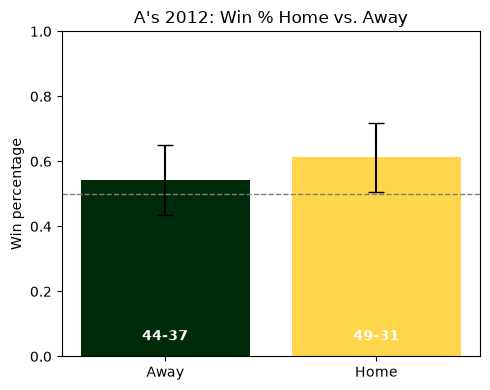

In [14]:
from src.analysis import plot_win_pct_by_site
fig = plot_win_pct_by_site(t, "A's 2012: Win % Home vs. Away")